# ROC and precision–recall for common epitopes

How well do TRB receptors rank above supplied controls? Evaluate NLVPMVATV, ELAGIGILTV, LLLGIGILV and LLWNGPMAV, then connect ROC/PR curves to score overlap and true/false-positive counts.

The notebook scores all 2,670 source observations through the installed CLI against pinned, source-curated VDJdb, with exact self evidence excluded. It fits no model or deployment cutoff.

**Before you start**

Install `vdjmatch[bench,notebook]` and `ipykernel`. Open from the repository root or the complete `examples` directory. Set `AIRR_BENCHMARK` if your local mirror is elsewhere (default: `~/hf/airr_benchmark`).

## 1. Environment and budget

One observation is a benchmark source row with an anchor-inclusive junction, V/J calls and full peptide–MHC (pMHC) label. This lesson uses human TRB only. Four native workers share one query batch; numerical helper pools use one thread. Each CLI invocation has a 300-second limit.

In [ ]:
# Set budgets before numerical imports; every calculation uses a fresh CLI output directory.
import os, sys, json, tempfile, platform, subprocess, hashlib
from pathlib import Path
from importlib.metadata import version
THREADS = 4
for key in ("POLARS_MAX_THREADS", "OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[key] = "1"
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir())/"vdjmatch-matplotlib"))
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import psutil
examples = next(p for p in (Path.cwd()/"examples", Path.cwd()) if (p/"profile_cli.py").is_file())
sys.path.insert(0, str(examples))
from profile_cli import profile
output = Path(tempfile.mkdtemp(prefix="vdjmatch-scientific-example-"))
benchmark = Path(os.environ.get("AIRR_BENCHMARK", Path.home()/"hf/airr_benchmark"))
reference = benchmark/"vdjdb/vdjdb-2026-06-11-ZENODO/vdjdb_full.txt.gz"
if not reference.is_file():
    raise FileNotFoundError("Set AIRR_BENCHMARK to the complete local benchmark mirror")
print("Python", platform.python_version(), platform.machine())
for package in ("vdjmatch", "vdjtools", "seqtree", "polars", "matplotlib", "scikit-learn", "psutil"):
    print(package, version(package))
print("Logical CPUs:", psutil.cpu_count(), "physical cores:", psutil.cpu_count(logical=False),
      "RAM (GB):", round(psutil.virtual_memory().total/1e9, 1))
print("Fresh output directory:", output)
print("Reference SHA256:", hashlib.sha256(reference.read_bytes()).hexdigest())
# Consistent final-size typography and colour-blind-safe scientific encodings.
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":8, "axes.labelsize":8,
                    "axes.titlesize":9, "legend.fontsize":7, "xtick.labelsize":7,
                    "ytick.labelsize":7, "axes.spines.top":False, "axes.spines.right":False,
                    "pdf.fonttype":42, "svg.fonttype":"none", "figure.dpi":150})
COLORS = ["#0072B2", "#D55E00", "#009E73", "#CC79A7"]
def export(fig, name):
    for extension in ("pdf", "svg", "png"):
        fig.savefig(output/f"{name}.{extension}", dpi=300, bbox_inches="tight")


## 2. Load the labelled observations

Dataset 1 supplies NLV tetramer-positive and tetramer-negative observations. Dataset 2 supplies ELA, LLL and LLW binders with real repertoire controls matched by V usage and generation probability during benchmark construction. Keep every supplied label and observation.

`junction_aa` includes the conserved Cys and Phe/Trp anchors. HLA-A*02 labels have family resolution; the declared assay target uses compatible MHC matching.

In [ ]:
# Read both complete raw TRB panels and retain source identities and assay labels.
parts = [pl.read_csv(benchmark/f"vdjmatch/airr/dataset_{number}_TRB.tsv.gz", separator="\t")
         .with_columns(pl.lit(f"dataset_{number}").alias("dataset")) for number in (1, 2)]
raw = pl.concat(parts).with_row_index("query_id")
assert raw["junction_aa"].str.contains(r"^C[ACDEFGHIKLMNPQRSTVWY]+[FW]$").all()
assert set(raw["binder"].unique()) == {0, 1}
PMHC = ["epitope", "mhc_a", "mhc_b", "mhc_class"]
print(raw.group_by(PMHC+["binder"]).len().sort(PMHC+["binder"]))
raw.write_csv(output/"queries.tsv", separator="\t")


shape: (8, 6)
┌────────────┬──────────┬───────┬───────────┬────────┬─────┐
│ epitope    ┆ mhc_a    ┆ mhc_b ┆ mhc_class ┆ binder ┆ len │
│ ---        ┆ ---      ┆ ---   ┆ ---       ┆ ---    ┆ --- │
│ str        ┆ str      ┆ str   ┆ str       ┆ i64    ┆ u32 │
╞════════════╪══════════╪═══════╪═══════════╪════════╪═════╡
│ ELAGIGILTV ┆ HLA-A*02 ┆ B2M   ┆ MHCI      ┆ 0      ┆ 888 │
│ ELAGIGILTV ┆ HLA-A*02 ┆ B2M   ┆ MHCI      ┆ 1      ┆ 898 │
│ LLLGIGILV  ┆ HLA-A*02 ┆ B2M   ┆ MHCI      ┆ 0      ┆ 232 │
│ LLLGIGILV  ┆ HLA-A*02 ┆ B2M   ┆ MHCI      ┆ 1      ┆ 233 │
│ LLWNGPMAV  ┆ HLA-A*02 ┆ B2M   ┆ MHCI      ┆ 0      ┆ 86  │
│ LLWNGPMAV  ┆ HLA-A*02 ┆ B2M   ┆ MHCI      ┆ 1      ┆ 87  │
│ NLVPMVATV  ┆ HLA-A*02 ┆ B2M   ┆ MHCI      ┆ 0      ┆ 225 │
│ NLVPMVATV  ┆ HLA-A*02 ┆ B2M   ┆ MHCI      ┆ 1      ┆ 21  │
└────────────┴──────────┴───────┴───────────┴────────┴─────┘


## 3. Calculate target evidence

`neighbours` exposes the detailed assay-target route. The flags below select annotation's stem4 BLOSUM62 kernel. `--targets-from-sample` declares the assayed pMHC; the scorer never reads `binder`. `--exclude-exact` removes the query junction from reference evidence and population counts, while retaining the complete curated background.

In [ ]:
# Execute one native batch for this population; profile two fresh runs, never cached predictions.
base = [sys.executable, "-m", "vdjmatch.cli", "neighbours", str(output/"queries.tsv"),
        "--vdjdb", str(reference), "--locus", "TRB", "--targets-from-sample",
        "--reference-population", "curated-benchmark", "--exclude-exact",
        "--distance-matrix", "blosum62", "--junction-ends", "trim3", "--stem-depth", "4",
        "--neighbour-weighting", "kernel", "--background", "vdjdb-other"]
resources = []
for threads in (1, THREADS):
    command = base + ["--threads", str(threads), "--output-prefix", str(output/f"trb-{threads}")]
    result = profile(command, output/f"trb-{threads}.log", timeout=300)
    resources.append({"workflow":"Assayed TRB", "queries":raw.height, "native_threads":threads, **result})
    print(threads, "threads:", round(result["seconds"], 2), "s;", round(result["peak_tree_rss_GB"], 3), "GB")


## 4. Verify identity and thread equality

One- and four-thread evidence must match exactly. Join by query identity and full pMHC so shared junctions and contradictory labels remain distinct. Retain unsupported observations in metric denominators; missing scores rank below every finite score.

In [ ]:
# Verify the two full CLI evidence tables and join all source observations without dropping no-hits.
a = pl.read_csv(output/"trb-1.enrichment.tsv", separator="\t").sort(["query_id", *PMHC])
b = pl.read_csv(output/f"trb-{THREADS}.enrichment.tsv", separator="\t").sort(["query_id", *PMHC])
assert a.equals(b), "Serial and parallel evidence differ"
assert a.height == raw.height
scored = raw.join(b, on=["query_id", *PMHC], how="left", validate="1:1", nulls_equal=True)
assert scored.height == raw.height
finite = scored["kernel_score"].drop_nulls().to_numpy()
finite = finite[np.isfinite(finite)]
sentinel = np.nextafter(finite.min(), -np.inf) if finite.size else -1.0
scored = scored.with_columns(pl.when(pl.col("kernel_score").is_finite()).then(pl.col("kernel_score"))
                            .otherwise(pl.lit(sentinel)).alias("ranking_score"))
print(scored.group_by("epitope", "kernel_status").len().sort("epitope", "kernel_status"))
scored.write_csv(output/"scored-observations.tsv", separator="\t")


## 5. Calculate ROC-AUC and average precision

ROC-AUC measures positive-versus-control ranking, with half credit for ties. Average precision (AP) summarizes precision–recall without trapezoidal interpolation. Read AP alongside each task's positive fraction: NLV has a different class balance.

In [ ]:
# Compute descriptive metrics from fresh CLI scores; no fitted threshold or significance test.
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
curves, metrics = {}, []
for key, part in scored.group_by(PMHC, maintain_order=True):
    y, score = part["binder"].to_numpy(), part["ranking_score"].to_numpy()
    fpr, tpr, thresholds = roc_curve(y, score, drop_intermediate=False)
    precision, recall, _ = precision_recall_curve(y, score)
    curves[key[0]] = (fpr, tpr, thresholds, precision, recall, y, score)
    metrics.append(dict(zip(PMHC, key)) | {"observations":len(y), "positives":int(y.sum()),
        "controls":int((y==0).sum()), "positive_fraction":float(y.mean()),
        "ROC_AUC":roc_auc_score(y, score), "average_precision":average_precision_score(y, score)})
summary = pl.DataFrame(metrics).sort("epitope")
summary.write_csv(output/"accuracy.tsv", separator="\t")
print(summary)


shape: (4, 10)
┌────────────┬──────────┬───────┬───────────┬───┬──────────┬──────────────┬──────────┬─────────────┐
│ epitope    ┆ mhc_a    ┆ mhc_b ┆ mhc_class ┆ … ┆ controls ┆ positive_fra ┆ ROC_AUC  ┆ average_pre │
│ ---        ┆ ---      ┆ ---   ┆ ---       ┆   ┆ ---      ┆ ction        ┆ ---      ┆ cision      │
│ str        ┆ str      ┆ str   ┆ str       ┆   ┆ i64      ┆ ---          ┆ f64      ┆ ---         │
│            ┆          ┆       ┆           ┆   ┆          ┆ f64          ┆          ┆ f64         │
╞════════════╪══════════╪═══════╪═══════════╪═══╪══════════╪══════════════╪══════════╪═════════════╡
│ ELAGIGILTV ┆ HLA-A*02 ┆ B2M   ┆ MHCI      ┆ … ┆ 888      ┆ 0.5028       ┆ 0.573543 ┆ 0.577983    │
│ LLLGIGILV  ┆ HLA-A*02 ┆ B2M   ┆ MHCI      ┆ … ┆ 232      ┆ 0.501075     ┆ 0.717312 ┆ 0.741979    │
│ LLWNGPMAV  ┆ HLA-A*02 ┆ B2M   ┆ MHCI      ┆ … ┆ 86       ┆ 0.50289      ┆ 0.455894 ┆ 0.498641    │
│ NLVPMVATV  ┆ HLA-A*02 ┆ B2M   ┆ MHCI      ┆ … ┆ 225      ┆ 0.085366     ┆ 

## 6. Compare ROC and precision–recall

ROC shows positive recovery per control admitted; PR shows the positive fraction among admitted observations. Colours and line styles identify the same epitope in both panels. The preceding table gives exact positive/control counts; the legends give AUC and AP.

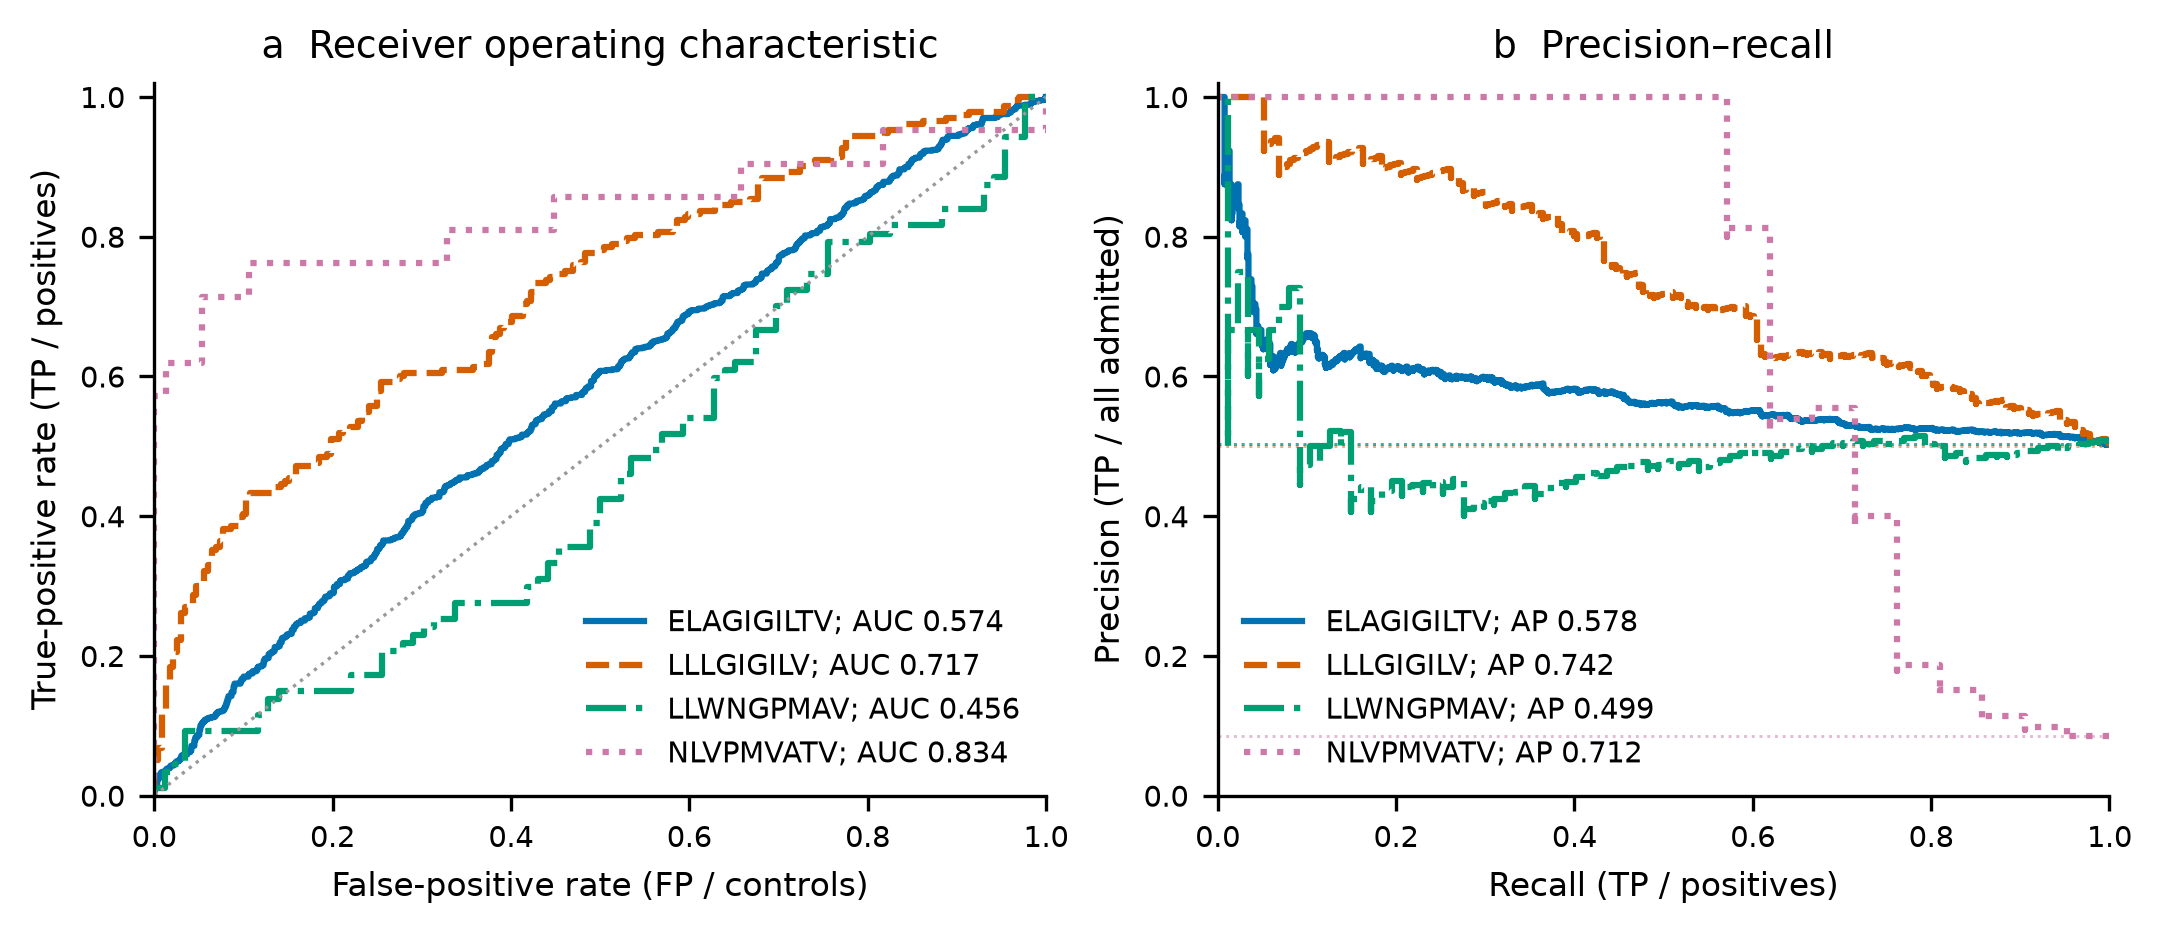

In [ ]:
# Draw aligned ROC and PR panels at 180 mm width, with direct class-balance references.
fig, axes = plt.subplots(1, 2, figsize=(7.09, 3.0), layout="constrained")
styles = ["-", "--", "-.", ":"]
for i, row in enumerate(summary.iter_rows(named=True)):
    ep = row["epitope"]; fpr,tpr,thresholds,precision,recall,y,score = curves[ep]
    label = f"{ep} (n+={row['positives']}, n−={row['controls']})"
    axes[0].plot(fpr,tpr,color=COLORS[i],ls=styles[i],lw=1.5,
                 label=ep+f"; AUC {row['ROC_AUC']:.3f}")
    axes[1].step(recall,precision,where="post",color=COLORS[i],ls=styles[i],lw=1.5,
                 label=ep+f"; AP {row['average_precision']:.3f}")
    axes[1].axhline(row["positive_fraction"],color=COLORS[i],lw=.7,ls=":",alpha=.5)
axes[0].plot([0,1],[0,1],color="0.6",lw=.8,ls=":")
for ax, title in zip(axes,["a  Receiver operating characteristic", "b  Precision–recall"]):
    ax.set(xlim=(0,1),ylim=(0,1.02),title=title)
    ax.legend(frameon=False,loc="lower right" if ax is axes[0] else "lower left")
axes[0].set(xlabel="False-positive rate (FP / controls)",ylabel="True-positive rate (TP / positives)")
axes[1].set(xlabel="Recall (TP / positives)",ylabel="Precision (TP / all admitted)")
export(fig,"roc-pr"); plt.show()


**Figure 1 | Discrimination of supplied TRB positive/control labels.** **a**, ROC curves for all source observations, including unsupported queries. The diagonal identifies equal positive/control ranking. **b**, Precision–recall curves at the observed class balance; colour-matched dotted horizontal lines indicate each task’s positive fraction. Each source query is one observation; counts and descriptive AUC/AP values are computed from the fresh CLI table. These are target-specific ranking measurements, with exact self evidence excluded, rather than calibrated all-label call rates.

## 7. Inspect score overlap

Empirical cumulative distributions show all scores without histogram bins or density smoothing. Logarithmic evidence axes reveal the occupied range and tail. Blue solid lines represent positives; orange dashed lines represent supplied controls.

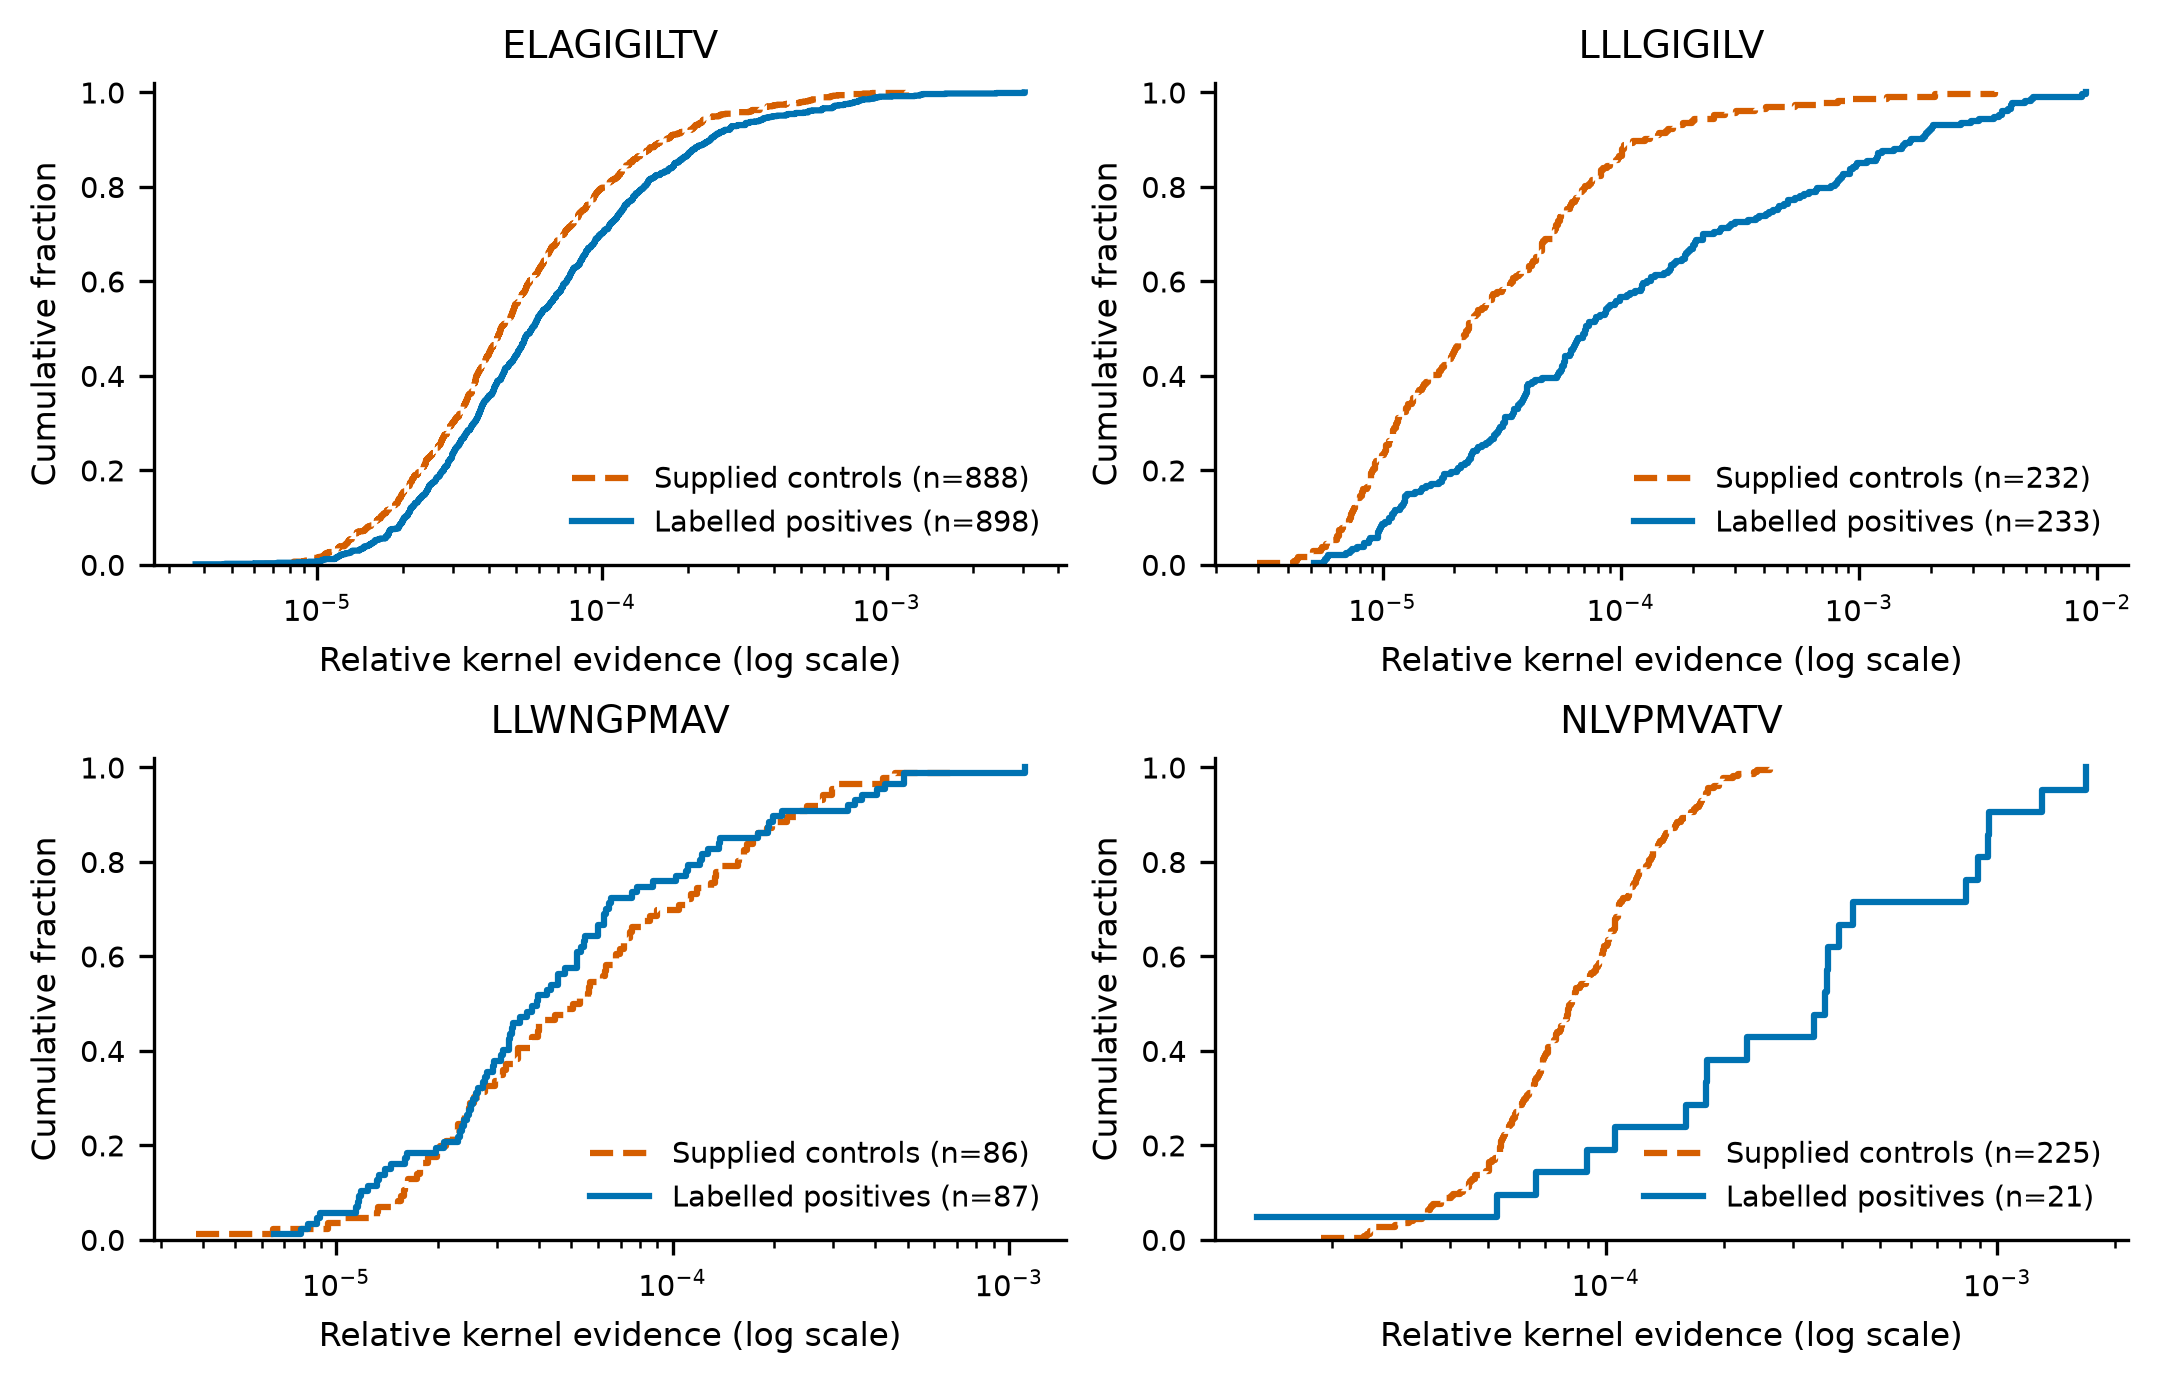

In [ ]:
# Plot class-specific ECDFs; sample size affects steps, not a fitted density estimate.
fig, axes = plt.subplots(2,2,figsize=(7.09,4.5),layout="constrained")
for ax, row in zip(axes.flat,summary.iter_rows(named=True)):
    *_, y, score = curves[row["epitope"]]
    for value,color,label,style in [(0,"#D55E00","Supplied controls","--"),(1,"#0072B2","Labelled positives","-")]:
        values=np.sort(score[y==value]); ax.step(values,np.arange(1,len(values)+1)/len(values),
            where="post",color=color,ls=style,label=f"{label} (n={len(values)})")
    ax.set(xscale="log",title=row["epitope"],xlabel="Relative kernel evidence (log scale)",ylabel="Cumulative fraction",ylim=(0,1.02))
    ax.legend(frameon=False,loc="lower right")
export(fig,"score-distributions");plt.show()


**Figure 2 | Positive/control score distributions.** Empirical cumulative fractions for supplied positives (blue solid) and controls (orange dashed), with exact observation counts and logarithmic evidence axes. Larger evidence values indicate stronger relative target support. The distributions preserve ties and unsupported observations; no density smoothing or fitted separation model is used.

## 8. Count true and false positives

At each observed threshold, admit all scores at least that large. Tied observations enter together. TP counts supplied positives and FP counts supplied controls; the trajectory recommends no cutoff. FN and TN remain in the exported table.

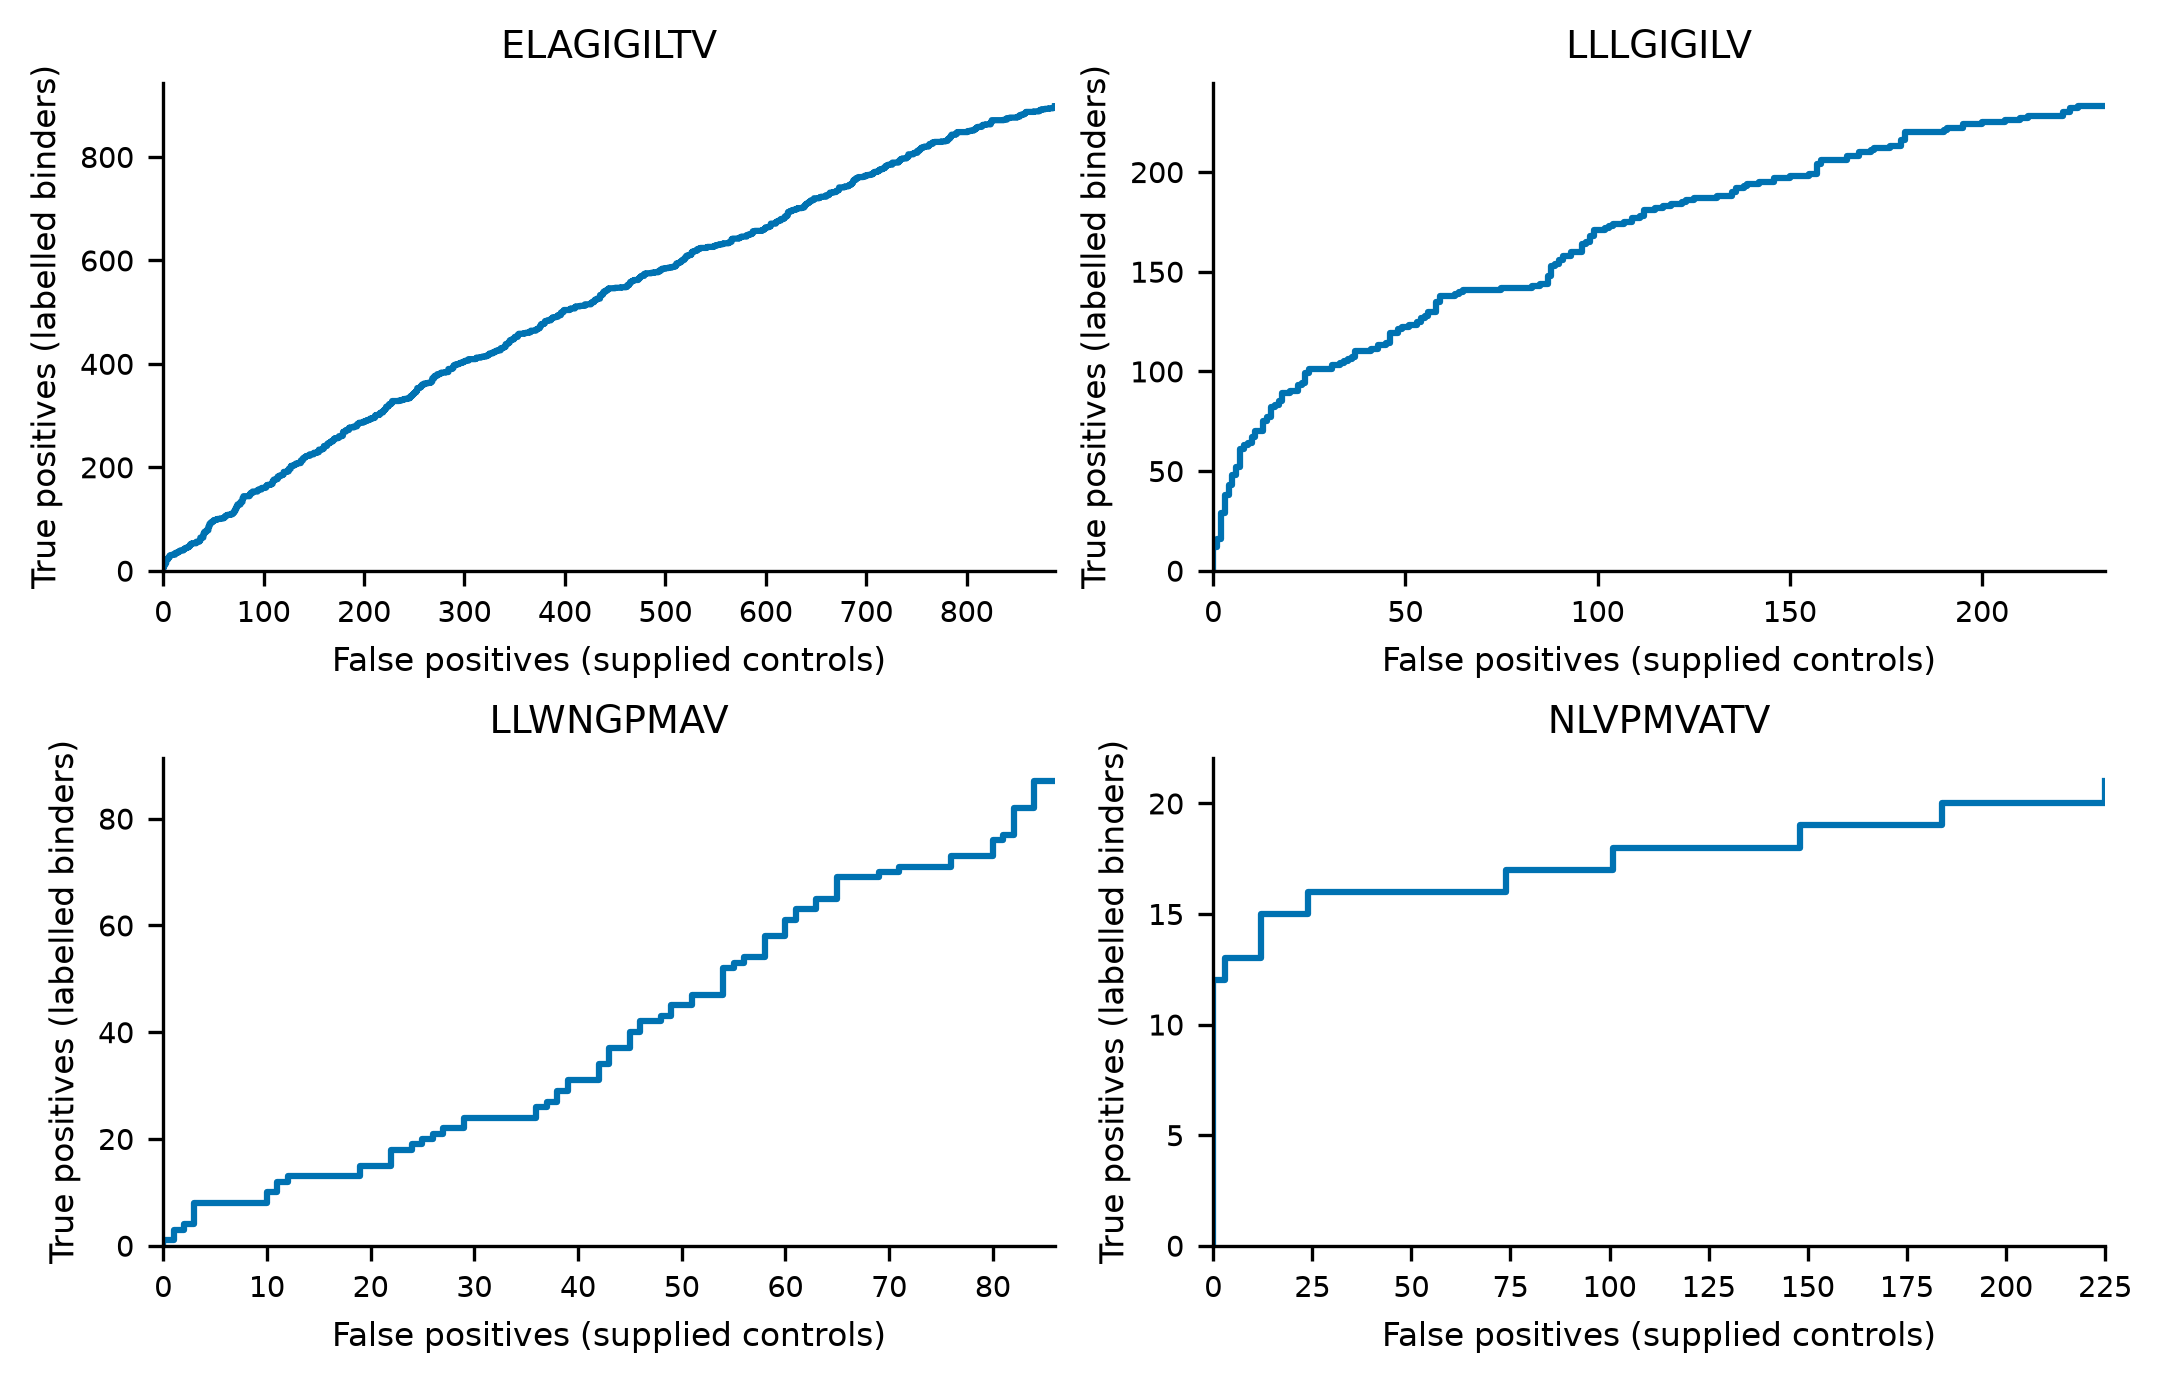

In [ ]:
# Convert all observed ROC thresholds to exact integer counts, retaining score ties.
count_rows=[]
fig,axes=plt.subplots(2,2,figsize=(7.09,4.5),layout="constrained")
for ax,row in zip(axes.flat,summary.iter_rows(named=True)):
    fpr,tpr,thresholds,*_=curves[row["epitope"]]
    fp=np.rint(fpr*row["controls"]).astype(int);tp=np.rint(tpr*row["positives"]).astype(int)
    ax.step(fp,tp,where="post",color="#0072B2",lw=1.5)
    ax.set(title=row["epitope"],xlabel="False positives (supplied controls)",ylabel="True positives (labelled binders)",
           xlim=(0,row["controls"]),ylim=(0,row["positives"]*1.05))
    for cutoff,p,n in zip(thresholds,tp,fp):
        count_rows.append({"epitope":row["epitope"],"score_threshold":float(cutoff),
                          "TP":int(p),"FP":int(n),"FN":row["positives"]-int(p),"TN":row["controls"]-int(n)})
pl.DataFrame(count_rows).write_csv(output/"operating-counts.tsv",separator="\t")
export(fig,"true-false-positive-counts");plt.show()


**Figure 3 | Recovery and false-positive counts across observed evidence thresholds.** Each step admits an entire score-tied group. TP and FP count source rows with supplied labels 1 and 0, respectively; FN/TN remain in the exported table. The endpoints include the complete positive/control populations. The plot describes a ranking trade-off and does not select or calibrate a deployment cutoff.

## 9. Report runtime and RAM

Elapsed time includes CLI startup, loading, scoring and export. RSS is the sampled sum over the CLI and descendants in decimal GB. CPU seconds divided by elapsed seconds give average occupied cores; live threads also include idle pools. Plotting and the notebook kernel are outside this measurement.

In [ ]:
# Export both complete fresh-run resource observations and verify evidence equality above.
resource_table=pl.DataFrame(resources)
resource_table.write_csv(output/"resources.tsv",separator="\t")
print(resource_table)
print("Measured wall-time ratio (1 / 4 threads):",resources[0]["seconds"]/resources[1]["seconds"])


## Interpretation and limits

ROC/AP describe ranking; the TP/FP trajectory describes its count trade-off without choosing a cutoff.

- The two datasets have different control origins and class balances. Supplied controls can contain unrecognised binders; labels remain unchanged.
- This is assayed-target scoring. All-label selected calls require separate calibration, and calibration does not transfer between geometries.
- Resource estimates cover these 2,670 human TRB observations on the recorded host; larger workloads need measurement.

Fresh TSVs, PDF/SVG and 300-dpi PNG figures are in the output directory. CLI manifests and source tables retain the recipe and identities; original identifiers and raw rows stay private.